In [3]:
# Inspect dataset quality

import pandas as pd


df = pd.read_csv("../data/heart.csv")

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Check target distribution
print("\nTarget distribution:")
print(df["target"].value_counts())

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing values: 0

Duplicate records: 723

Target distribution:
target
1    526
0    499
Name: count, dtype: int64


In [4]:
# Handle duplicate records
# Store the original dataset size
original_rows = df.shape[0]

# Remove exact duplicate rows
df = df.drop_duplicates()

# Reset row numbering
df = df.reset_index(drop=True)

# Calculate removed records
removed_rows = original_rows - df.shape[0]

# Display results
print("Original records:", original_rows)
print("Remaining records:", df.shape[0])
print("Removed duplicate records:", removed_rows)

Original records: 1025
Remaining records: 302
Removed duplicate records: 723


In [9]:
# Separate features and target
# Separate input features
X = df.drop("target", axis=1)

# Separate target variable
y = df["target"]

# Display dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (302, 13)
Target shape: (302,)


In [10]:
# Split training and testing datasets
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (241, 13)
Testing features: (61, 13)
Training target: (241,)
Testing target: (61,)


In [11]:
# Build a preprocessing pipeline
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Import OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

# Import ColumnTransformer
from sklearn.compose import ColumnTransformer

# Import Pipeline
from sklearn.pipeline import Pipeline

In [12]:
#Define feature groups
 # Numerical features
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

# Categorical features
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

In [13]:
# Create numerical preprocessing
# Create numerical preprocessing pipeline
numerical_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

In [14]:
# Create categorical preprocessing
# Create categorical preprocessing pipeline
categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

In [15]:
# Combine both preprocessing pipelines
# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
# Verify our preprocessing preparation
# Check class distribution
# Training target distribution
print("Training class distribution:")
print(y_train.value_counts(normalize=True) * 100)

# Testing target distribution
print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training class distribution:
target
1    54.356846
0    45.643154
Name: proportion, dtype: float64

Testing class distribution:
target
1    54.098361
0    45.901639
Name: proportion, dtype: float64


In [17]:
# Verify feature columns
# Check training feature columns
print("Training columns:")
print(X_train.columns.tolist())

# Check whether all expected features are present
print("\nTotal input features:", X_train.shape[1])

Training columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Total input features: 13


In [18]:
# Display configured preprocessing steps
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'ca', 'thal'])])


In [19]:
# Import Logistic Regression classifier
from sklearn.linear_model import LogisticRegression

In [20]:
# Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [21]:
# Train Logistic Regression model
logistic_model.fit(X_train, y_train)

# Display confirmation
print("Logistic Regression training completed!")

Logistic Regression training completed!


In [22]:
# Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

In [23]:
# Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

In [24]:
# Train Random Forest model
random_forest_model.fit(X_train, y_train)

# Display confirmation
print("Random Forest training completed!")

Random Forest training completed!


### Evaluate both models

In [25]:
# Import evaluation libraries
# Import accuracy score
from sklearn.metrics import accuracy_score

# Import precision score
from sklearn.metrics import precision_score

# Import recall score
from sklearn.metrics import recall_score

# Import F1 score
from sklearn.metrics import f1_score

# Import confusion matrix
from sklearn.metrics import confusion_matrix

# Import classification report
from sklearn.metrics import classification_report

In [26]:
# Predict using Logistic Regression
logistic_predictions = logistic_model.predict(X_test)

# Predict using Random Forest
random_forest_predictions = random_forest_model.predict(X_test)

print("Both models generated predictions successfully!")

Both models generated predictions successfully!


In [27]:
# Evalute Logistic Regression model
# Calculate Logistic Regression metrics
logistic_accuracy = accuracy_score(y_test, logistic_predictions)

logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

# Display results
print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1 Score :", logistic_f1)

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy : 0.8360655737704918
Precision: 0.8484848484848485
Recall   : 0.8484848484848485
F1 Score : 0.8484848484848485


In [29]:
# Evaluate Random Forest model
# Calculate Random Forest metrics
rf_accuracy = accuracy_score(y_test, random_forest_predictions)

rf_precision = precision_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    random_forest_predictions,
    zero_division=0
)

# Display results
print("RANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

RANDOM FOREST RESULTS
---------------------
Accuracy : 0.8032786885245902
Precision: 0.8181818181818182
Recall   : 0.8181818181818182
F1 Score : 0.8181818181818182


In [ ]:
# Compare both models

# Create model comparison DataFrame
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1
    ]
})

# Display comparison
comparison.round(4)


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8361,0.8485,0.8485,0.8485
1,Random Forest,0.8033,0.8182,0.8182,0.8182


In [31]:
# Classification reports
# Logistic Regression classification report
print("LOGISTIC REGRESSION")
print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=[
            "Absence of Heart Disease",
            "Presence of Heart Disease"
        ],
        zero_division=0
    )
)

# Random Forest classification report
print("RANDOM FOREST")
print(
    classification_report(
        y_test,
        random_forest_predictions,
        target_names=[
            "Absence of Heart Disease",
            "Presence of Heart Disease"
        ],
        zero_division=0
    )
)

LOGISTIC REGRESSION
                           precision    recall  f1-score   support

 Absence of Heart Disease       0.82      0.82      0.82        28
Presence of Heart Disease       0.85      0.85      0.85        33

                 accuracy                           0.84        61
                macro avg       0.83      0.83      0.83        61
             weighted avg       0.84      0.84      0.84        61

RANDOM FOREST
                           precision    recall  f1-score   support

 Absence of Heart Disease       0.79      0.79      0.79        28
Presence of Heart Disease       0.82      0.82      0.82        33

                 accuracy                           0.80        61
                macro avg       0.80      0.80      0.80        61
             weighted avg       0.80      0.80      0.80        61



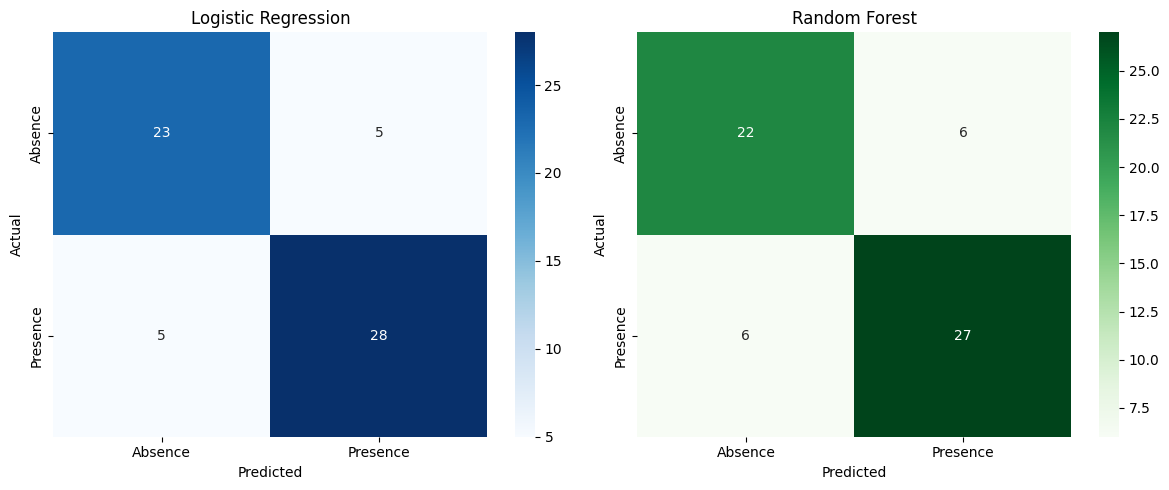

In [32]:
# Visualize confusion matrices
# Create a figure with two subplots

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Calculate Logistic Regression confusion matrix
logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=[0, 1]
)

# Plot Logistic Regression matrix
sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Absence", "Presence"],
    yticklabels=["Absence", "Presence"],
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Calculate Random Forest confusion matrix
rf_cm = confusion_matrix(
    y_test,
    random_forest_predictions,
    labels=[0, 1]
)

# Plot Random Forest matrix
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Absence", "Presence"],
    yticklabels=["Absence", "Presence"],
    ax=axes[1]
)

axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

# Adjust spacing
plt.tight_layout()

# Display charts
plt.show()

In [33]:
# Import Joblib
import joblib

In [34]:
# Select Logistic Regression as our final model
final_model = logistic_model

# Display selected model
print("Selected model:", final_model.named_steps["classifier"])

Selected model: LogisticRegression(max_iter=1000, random_state=42)


In [35]:
# Save the complete trained pipeline
joblib.dump(
    final_model,
    "../model/heart_model.joblib"
)

# Display confirmation
print("Model saved successfully!")

Model saved successfully!


In [36]:
# Load the saved model
loaded_model = joblib.load(
    "../model/heart_model.joblib"
)

# Verify that the model loaded
print("Model loaded successfully!")

# Display the loaded model
print(loaded_model)

Model loaded successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))]

In [37]:
# Select one patient record from testing data
sample_patient = X_test.iloc[[0]]

# Generate prediction
prediction = loaded_model.predict(sample_patient)

# Generate prediction probability
probability = loaded_model.predict_proba(sample_patient)

# Display result
print("Predicted class:", prediction[0])
print("Prediction probability:", probability[0])

# Interpret prediction
if prediction[0] == 1:
    print("Educational prediction: Presence of heart disease")
else:
    print("Educational prediction: Absence of heart disease")

Predicted class: 0
Prediction probability: [0.78443325 0.21556675]
Educational prediction: Absence of heart disease
